# Lecture 18
## Comparing distributions and groups with seaborn
## Miles Chen, PhD

**What does this plot summarize, and which observations contribute?**

Seaborn builds on Matplotlib and can map table columns to positions, colors, and panels.
Some functions also calculate statistics before drawing.

Keep asking: **What does one input row represent? What does one mark represent?**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
titanic = pd.read_csv("../data/titanic.csv")
print("seaborn version:", sns.__version__)
print("Passenger records:", len(titanic))
titanic.head()

seaborn version: 0.13.2
Passenger records: 891


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Rebuild analysis tables

In [2]:
class_order = ["First", "Second", "Third"]
sex_order = ["female", "male"]
class_labels = pd.DataFrame({"pclass": [1, 2, 3], "class_name": class_order})
passengers = titanic.merge(class_labels, on="pclass", how="left", validate="many_to_one")
group_summary = (
    titanic.groupby(["pclass", "sex"], as_index=False, dropna=False)
    .agg(
        n_passengers=("passengerid", "size"),
        n_survival=("survived", "count"),
        survival_rate=("survived", "mean"),
        n_age=("age", "count"),
        mean_age=("age", "mean"),
    )
    .sort_values(["pclass", "sex"])
)
analysis_table = group_summary.merge(class_labels, on="pclass", how="left", validate="many_to_one")
plot_table = analysis_table[
    ["pclass", "class_name", "sex", "n_passengers", "n_survival", "survival_rate"]
].sort_values(["pclass", "sex"]).reset_index(drop=True)
print("Passenger rows:", len(passengers))
print("Summary rows:", len(plot_table))
print("Passenger records represented:", plot_table["n_passengers"].sum())
plot_table

Passenger rows: 891
Summary rows: 6
Passenger records represented: 891


,pclass,class_name,sex,n_passengers,n_survival,survival_rate
0,1,First,female,94,94,0.968085
1,1,First,male,122,122,0.368852
2,2,Second,female,76,76,0.921053
3,2,Second,male,108,108,0.157407
4,3,Third,female,144,144,0.500000
5,3,Third,male,347,347,0.135447


# Choose visual roles for columns

With a long-form table, `data=` supplies the table and `x=`, `y=`, and `hue=`
name columns.

If you have used ggplot2 in R, mapping named variables to visual roles is a
familiar idea.

**Axes-level** functions such as `scatterplot`, `histplot`, `boxplot`, and
`barplot` draw onto an Axes supplied through `ax=`. We can keep using
`ax.set_title()`, `ax.set_xlabel()`, and the other Matplotlib methods.

For this scatterplot, keep records with both age and fare. The color refers
to ticket class, so use the class labels as categories.

Paired observations: 714
Excluded records: 177


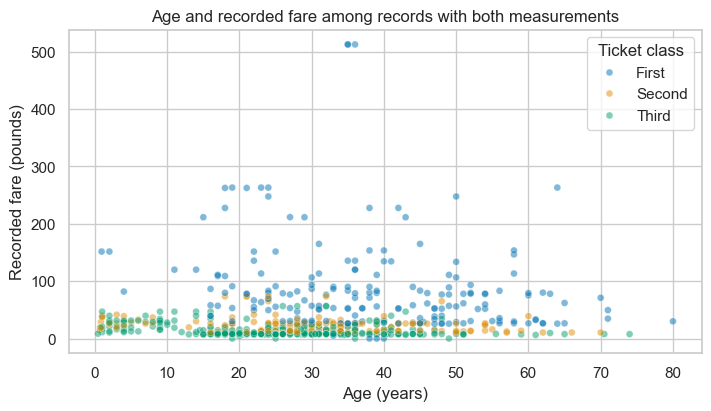

In [3]:
age_fare = passengers.dropna(subset=["age", "fare"])
print("Paired observations:", len(age_fare))
print("Excluded records:", len(passengers) - len(age_fare))
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sns.scatterplot(data=age_fare, x="age", y="fare", hue="class_name",
                hue_order=class_order, alpha=0.5, s=25, ax=ax)
ax.set(title="Age and recorded fare among records with both measurements",
       xlabel="Age (years)", ylabel="Recorded fare (pounds)")
ax.legend(title="Ticket class")
plt.show()

# histogram

An age histogram describes the 714 recorded ages

Avoid dropping
every row with any missing field: a missing cabin is irrelevant to this plot.

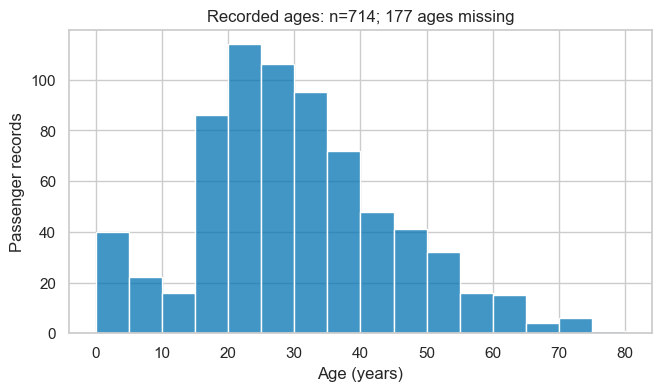

In [5]:
age_records = passengers.dropna(subset=["age"])
age_bins = np.arange(0, 85, 5) # set bins
fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
sns.histplot(data=age_records, x="age", bins=age_bins, ax=ax)
ax.set(title=f"Recorded ages: n={len(age_records)}; 177 ages missing",
       xlabel="Age (years)", ylabel="Passenger records")
plt.show()

# Counts and shapes

Raw histogram counts depend on both distribution shape and group size.
To compare shapes, the right panel normalizes each sex group's histogram
separately: `stat="density", common_norm=False`.

With density, the area within each group totals one.

In [6]:
age_counts = passengers.groupby("sex", as_index=False).agg(
    n_passengers=("passengerid", "size"), n_age=("age", "count")
)
age_counts

,sex,n_passengers,n_age
0,female,314,261
1,male,577,453


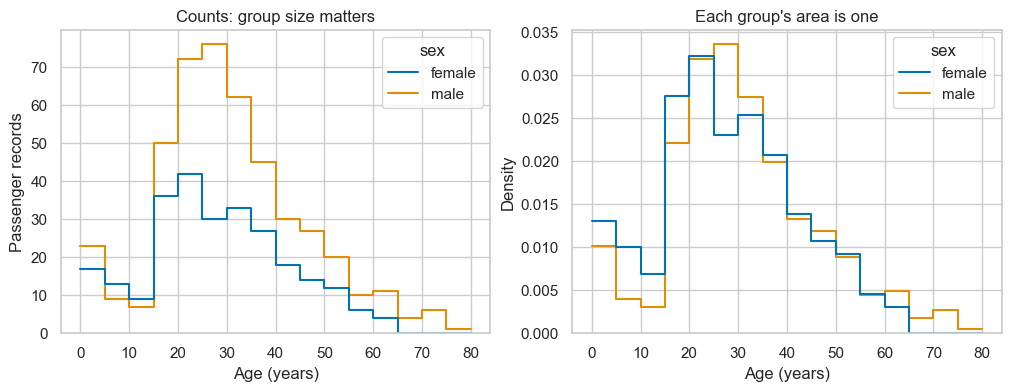

In [7]:
distribution_fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, layout="constrained")
sns.histplot(data=age_records, x="age", hue="sex", hue_order=sex_order,
             bins=age_bins, element="step", fill=False, ax=axes[0])
sns.histplot(data=age_records, x="age", hue="sex", hue_order=sex_order,
             bins=age_bins, element="step", fill=False,
             stat="density", common_norm=False, ax=axes[1])
axes[0].set(title="Counts: group size matters", ylabel="Passenger records")
axes[1].set(title="Each group's area is one", ylabel="Density")
for ax in axes:
    ax.set_xlabel("Age (years)")
plt.show()

# boxplots

A boxplot summarizes a numeric distribution within each category. The line
inside the box is the median; the box spans the middle 50% of observations.
By default, whiskers extend to observed values within 1.5 interquartile
ranges of the box, and more distant observations appear as separate points.

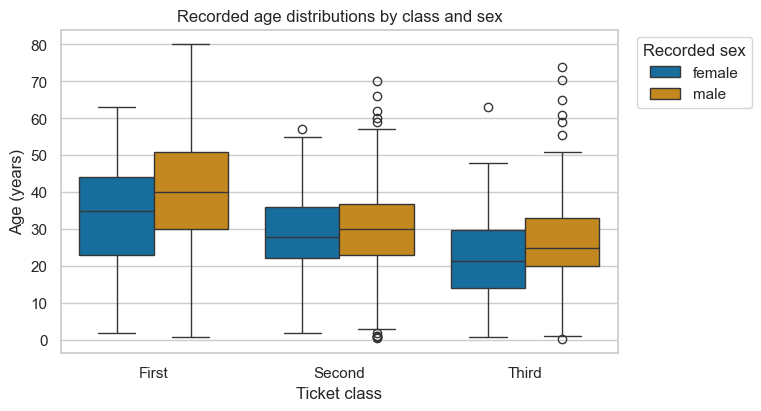

In [8]:
box_fig, ax = plt.subplots(figsize=(7.5, 4), layout="constrained")
sns.boxplot(data=age_records, x="class_name", y="age", hue="sex",
            order=class_order, hue_order=sex_order, ax=ax)
ax.set(title="Recorded age distributions by class and sex",
       xlabel="Ticket class", ylabel="Age (years)")
ax.legend(title="Recorded sex", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

| Function | What it does with the input rows |
| --- | --- |
| `scatterplot` | Places observations using their paired values |
| `histplot` | Groups numeric values into bins and counts or normalizes |
| `boxplot` | Computes distribution summaries within categories |
| `countplot` | Counts input rows within categories |
| `barplot` | By default, computes a mean and a confidence interval |

# `countplot`

Both tables have a `class_name` column. The left plot uses passenger records;
the right uses one row per class/sex group.

The right panel is intentionally a count of **summary rows**, not a plot
of the `n_passengers` values stored inside those rows.

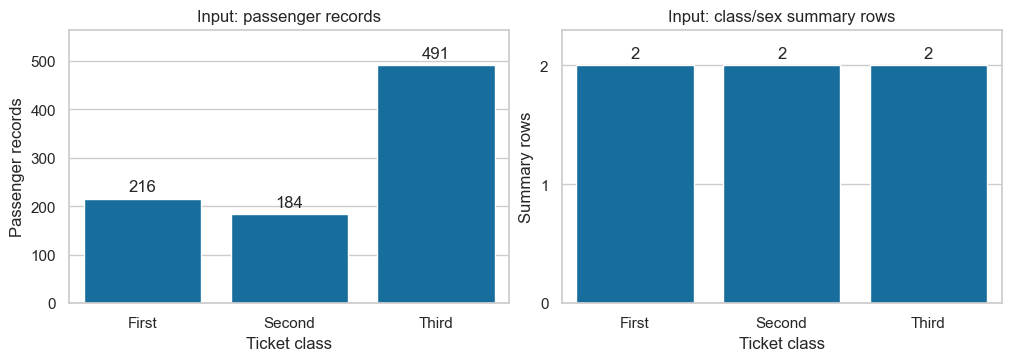

In [9]:
count_fig, count_axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
sns.countplot(data=passengers, x="class_name", order=class_order, ax=count_axes[0])
sns.countplot(data=plot_table, x="class_name", order=class_order, ax=count_axes[1])
count_axes[0].set(title="Input: passenger records", ylabel="Passenger records")
count_axes[1].set(title="Input: class/sex summary rows", ylabel="Summary rows")
count_axes[1].set_yticks([0, 1, 2])
for ax in count_axes:
    ax.set_xlabel("Ticket class")
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(y=0.15)
plt.show()

The passenger table gives **216, 184, and 491** records by class. The summary
table gives **2, 2, and 2** rows, because each class has two sex groups.

`countplot` did what it was asked to do. To plot a previously calculated
count, use that count as the height, or select an explicit aggregation of
the count column.

# Two routes to the same survival rates

For raw passenger records, a mean of the recorded 0/1 outcome gives the
survival rate. For `plot_table`, we have already computed one rate per group.

In both plots below, use class and sex as the grouping variables. Set
`errorbar=None` because our immediate goal is a descriptive display of the
recorded rates. Confirm that the heights agree.

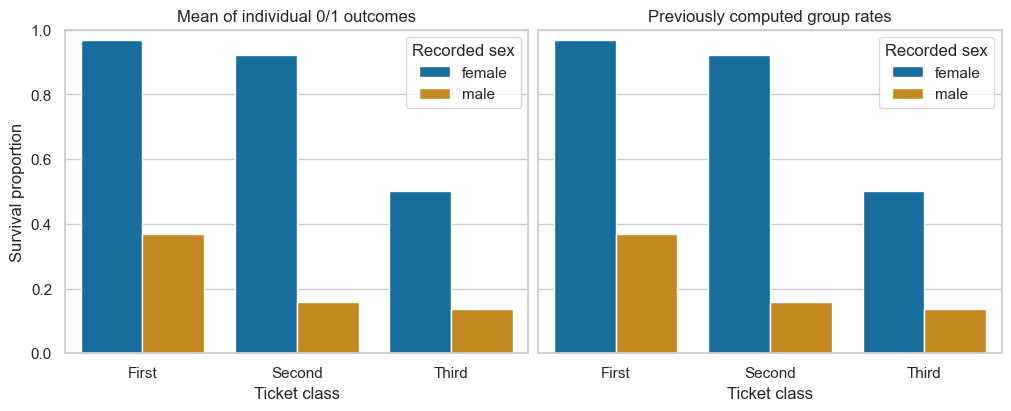

In [11]:
rate_fig, rate_axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
sns.barplot(data=passengers, x="class_name", y="survived", hue="sex",
            order=class_order, hue_order=sex_order, estimator="mean",
            errorbar=None, ax=rate_axes[0]) # note the estimator argument
sns.barplot(data=plot_table, x="class_name", y="survival_rate", hue="sex",
            order=class_order, hue_order=sex_order,
            errorbar=None, ax=rate_axes[1]) # there is no estimator argument here, we use y = "survival_rate"
rate_axes[0].set_title("Mean of individual 0/1 outcomes")
rate_axes[1].set_title("Previously computed group rates")
for ax in rate_axes:
    ax.set(xlabel="Ticket class", ylabel="Survival proportion", ylim=(0, 1))
    ax.legend(title="Recorded sex")
plt.show()

# Retain the denominators

The third-class female group has 72 recorded survivors among 144 recorded
outcomes: a rate of 0.50. The rate is the same in both panels.

We did not filter on age, so all 891 recorded outcomes contribute to the
comparisons.

# Default error bars are another statistical operation

With raw observations, `barplot` normally adds a bootstrap 95% confidence
interval for the estimated mean.

Choose intervals only after deciding what uncertainty or spread you want
to show and whether the assumptions fit the data.

# Facets repeat a plot across subsets

**Figure-level** functions such as `catplot`, `relplot`, and `displot` create
and manage their own figure, usually returning a `FacetGrid`.

Use `col=` or `row=` to assign subsets to panels. Use `hue=` to assign colors
within panels.

Do not pass an existing `ax=` to these figure-level functions. Use their
returned object to set labels and titles.

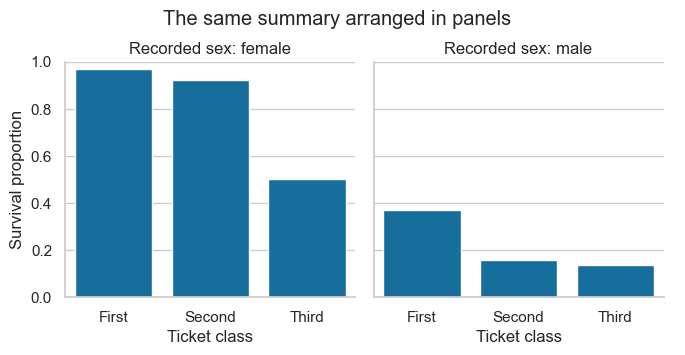

In [13]:
survival_grid = sns.catplot(
    data=plot_table, x="class_name", y="survival_rate", col="sex",
    kind="bar", order=class_order, col_order=sex_order,
    errorbar=None, height=3.4, aspect=1,
) # we create a grid of bar plots, one for each sex with the argument col="sex"
survival_grid.set_axis_labels("Ticket class", "Survival proportion")
survival_grid.set_titles("Recorded sex: {col_name}") # we use curly braces to indicate the column name
survival_grid.set(ylim=(0, 1))
survival_grid.figure.suptitle("The same summary arranged in panels", y=1.04)
plt.show()

# Which interface fits the task?

| Task | Start with |
| --- | --- |
| Draw on an Axes you already created | `sns.histplot(..., ax=ax)` or another axes-level function |
| Repeat a statistical plot across categories | `sns.displot`, `sns.catplot`, or `sns.relplot` with `row`/`col` |
| Customize an axes-level result | Matplotlib methods on `ax` |
| Customize a facet grid | `g.set_axis_labels()`, `g.set_titles()`, `g.set()` |
| Save a result | `fig.savefig(...)` or `g.savefig(...)` |

The methods fit together; you do not need to relearn labeling from scratch.

# Penguins Data

This dataset contains 344 penguin records, with species,
island, bill measurements, flipper length, body mass, and recorded sex.
Lengths are in millimeters and body mass is in grams.

We use the seaborn example copy of the Palmer Penguins data. The original
measurements were collected by Kristen Gorman and the Palmer Station LTER
program; see [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/).

In [14]:
penguins = pd.read_csv("../data/penguins.csv")
print("Penguin records:", len(penguins))
print("Missing values by column:")
print(penguins.isna().sum())
penguins.head()

Penguin records: 344
Missing values by column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


# Your turn: compare paired measurements across groups

Create a scatterplot of bill length (x) and flipper length (y), using species
for color and one panel per island.

1. Count how many records have both measurements and how many are excluded.
2. Choose an axes-level or figure-level function and explain your choice.
3. Label both measurements with units and use comparable scales across panels.
4. Write two sentences identifying what a point represents and which records
   contribute. Does a difference between island panels establish an island effect?

Hint: `sns.relplot(..., col="island")` makes the panels for you.

In [ ]:
# Prepare the plotting subset, create the figure, and write a caption.

# One solution

The plot requires the two measurements, species, and island. Recorded sex
is not a plotting variable here, so its missing values should not exclude
otherwise usable records.

Records shown: 342
Records excluded: 2


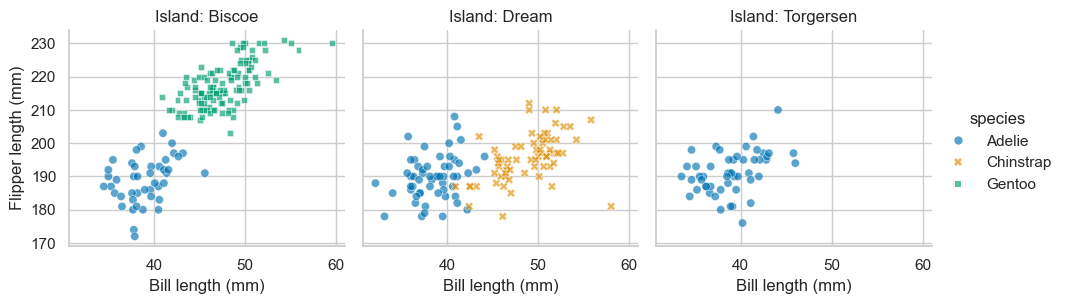

In [16]:
species_order = ["Adelie", "Chinstrap", "Gentoo"]
island_order = ["Biscoe", "Dream", "Torgersen"]
penguin_pairs = penguins.dropna(subset=["bill_length_mm", "flipper_length_mm", "species", "island"])
print("Records shown:", len(penguin_pairs))
print("Records excluded:", len(penguins) - len(penguin_pairs))
penguin_grid = sns.relplot(
    data=penguin_pairs, x="bill_length_mm", y="flipper_length_mm",
    hue="species", style="species", hue_order=species_order, style_order=species_order,
    col="island", col_order=island_order, alpha=0.65, height=3.2, aspect=1,
) # argument col="island" creates a grid of scatter plots, one for each island
# within each grid, points are colored and shaped by species, with the legend showing the species names
penguin_grid.set_axis_labels("Bill length (mm)", "Flipper length (mm)")
penguin_grid.set_titles("Island: {col_name}")
plt.show()

Each point represents one of the 342 penguin records with the two required
measurements, with species distinguished by color and shape and island by
panel; two records are excluded. The species represented differ across
islands, so differences between panels alone do not isolate an island effect.

# a heatmap uses the wide table directly

`pivot` puts one survival rate in each class/sex position.
A heatmap maps that matrix to colors.

Fix the color scale from 0 to 1 so colors have a consistent interpretation.
You should keep the group denominators in `plot_table`.

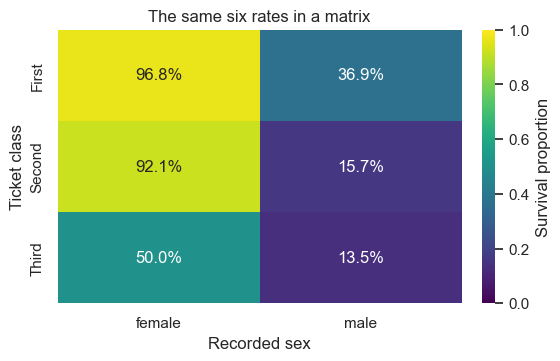

In [17]:
survival_wide = plot_table.pivot(index="class_name", columns="sex", values="survival_rate").reindex(
    index=class_order, columns=sex_order
)
fig, ax = plt.subplots(figsize=(5.5, 3.5), layout="constrained")
sns.heatmap(survival_wide, annot=True, fmt=".1%", vmin=0, vmax=1, cmap="viridis",
            cbar_kws={"label": "Survival proportion"}, ax=ax)
ax.set(title="The same six rates in a matrix", xlabel="Recorded sex", ylabel="Ticket class")
plt.show()

# `to_dict()` serves as a bridge from Polars

We can pass values computed in Polars to seaborn without repeating the
analysis in pandas. `to_dict(as_series=False)` produces a dictionary of
column names and ordinary Python lists, which seaborn accepts as `data`.
For a numeric distribution, we can pass a selected Series as a NumPy array.

Keep the exclusion explicit: the age array has 714 values; the survival
summary still represents all 891 passenger records.

Passenger records in the survival summary: 891
Values in the age array: 714


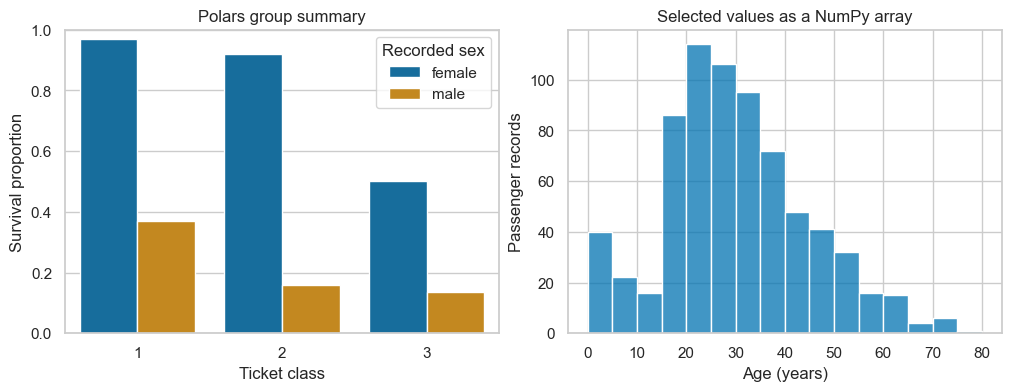

In [19]:
import polars as pl

titanic_pl = pl.read_csv("../data/titanic.csv")
polars_summary = titanic_pl.group_by(["pclass", "sex"]).agg(
    pl.len().alias("n_passengers"),
    pl.col("survived").mean().alias("survival_rate"),
).sort(["pclass", "sex"]) # create a summary table with the same structure as the pandas version
polars_plot_data = polars_summary.to_dict(as_series=False) # convert to a dictionary of lists for plotting
age_array = titanic_pl["age"].drop_nulls().to_numpy() # convert the age column to a NumPy array, dropping null values
print("Passenger records in the survival summary:", polars_summary["n_passengers"].sum())
print("Values in the age array:", len(age_array))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
sns.barplot(data=polars_plot_data, x="pclass", y="survival_rate", hue="sex",
            hue_order=sex_order, errorbar=None, ax=axes[0]) 
            # we use the plot_data dictionary of lists directly, with the same arguments as before
axes[0].set(xlabel="Ticket class", ylabel="Survival proportion", ylim=(0, 1), title="Polars group summary")
axes[0].legend(title="Recorded sex")
sns.histplot(x=age_array, bins=age_bins, ax=axes[1]) # use the age_array NumPy array directly
axes[1].set(xlabel="Age (years)", ylabel="Passenger records", title="Selected values as a NumPy array")
plt.show()

# uncertainty and spread are different

In the left plot, a bootstrap confidence interval describes uncertainty in
a group mean under the resampling assumptions, including treating the input
records as independent sampling units. On the right, one standard deviation
describes spread of individual body masses around the mean.

Neither is the range containing 95% of observations. A convenient default
does not establish that a dataset is a representative random sample.
`seed` makes the bootstrap example reproducible.

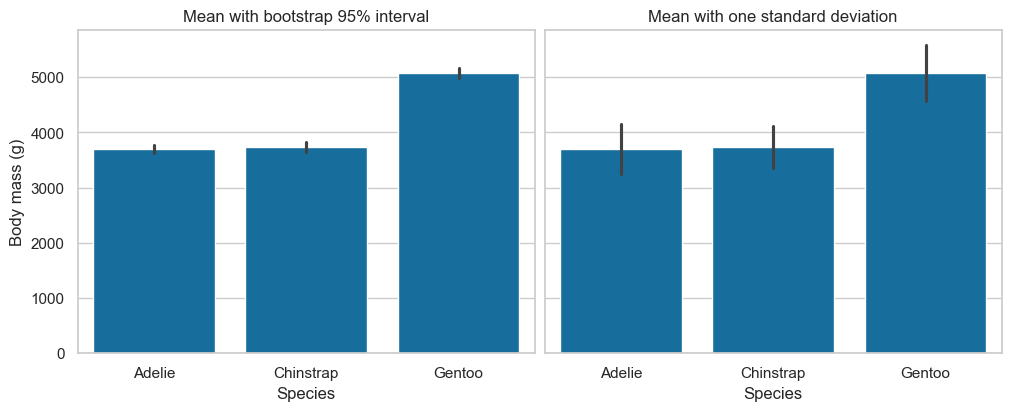

In [21]:
mass_records = penguins.dropna(subset=["species", "body_mass_g"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
sns.barplot(data=mass_records, x="species", y="body_mass_g", order=species_order,
            errorbar=("ci", 95), seed=21, ax=axes[0]) 
            # note the errorbar argument specifies a bootstrap 95% confidence interval
sns.barplot(data=mass_records, x="species", y="body_mass_g", order=species_order,
            errorbar="sd", ax=axes[1]) # note the errorbar argument specifies one standard deviation
axes[0].set_title("Mean with bootstrap 95% interval")
axes[1].set_title("Mean with one standard deviation")
for ax in axes:
    ax.set(xlabel="Species", ylabel="Body mass (g)")
plt.show()

# `lineplot` can aggregate repeated x-values

This fictional table has one row per device/day measurement. The left plot
connects daily means across devices. The right plot uses `units` to identify
separate trajectories and `estimator=None` to retain individual values.

Connecting points has a meaning here because each device is observed over
ordered days. We omit intervals to focus on the change in the row unit.

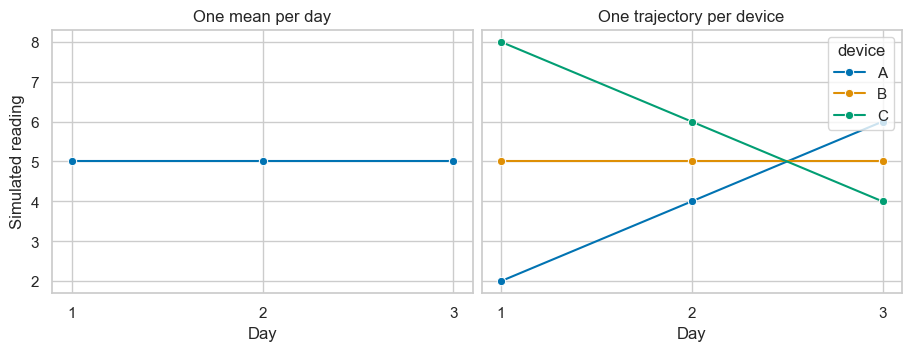

In [23]:
readings = pd.DataFrame({
    "day": [1, 1, 1, 2, 2, 2, 3, 3, 3],
    "device": ["A", "B", "C"] * 3,
    "reading": [2, 5, 8, 4, 5, 6, 6, 5, 4],
})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, layout="constrained")
sns.lineplot(data=readings, x="day", y="reading", marker="o", errorbar=None, ax=axes[0]) 
    # the mean is computed for each day
sns.lineplot(data=readings, x="day", y="reading", hue="device", units="device",
             estimator=None, errorbar=None, marker="o", ax=axes[1]) 
            # each device's trajectory is shown, with no averaging because we specify hue="device" and units="device"
axes[0].set_title("One mean per day")
axes[1].set_title("One trajectory per device")
for ax in axes:
    ax.set_xticks([1, 2, 3])
    ax.set(xlabel="Day", ylabel="Simulated reading")
plt.show()

# `displot`, rugs, and density estimates

A rug adds one small mark per observed value. A kernel density estimate
(KDE) smooths the distribution; its shape depends on the bandwidth.
A KDE curve is an estimate.

Below, `common_norm=False` normalizes each species curve separately.
`cut=0` restricts each curve's display to its observed range, but does not
by itself solve boundary bias in density estimation.

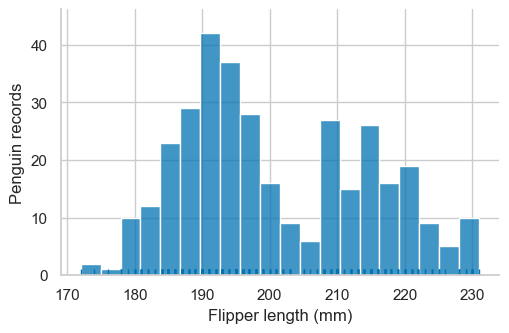

In [24]:
flipper_records = penguins.dropna(subset=["flipper_length_mm", "species"])
g = sns.displot(data=flipper_records, x="flipper_length_mm", bins=20, rug=True,
                height=3.5, aspect=1.5) # argument rug=True adds a rug plot along the x-axis
g.set_axis_labels("Flipper length (mm)", "Penguin records")
plt.show()

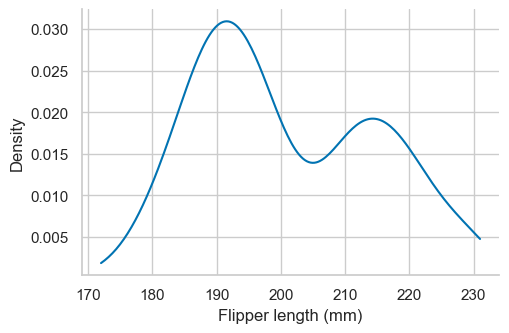

In [25]:
g = sns.displot(data=flipper_records, x="flipper_length_mm", kind="kde", cut=0,
                height=3.5, aspect=1.5) # argument cut=0 prevents the density from extending beyond the data range
g.set_axis_labels("Flipper length (mm)", "Density")
plt.show()

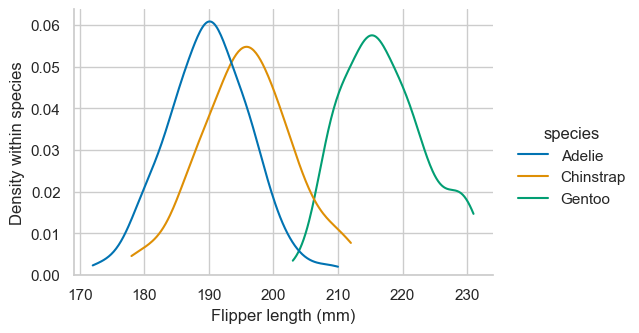

In [26]:
g = sns.displot(data=flipper_records, x="flipper_length_mm", hue="species",
                hue_order=species_order, kind="kde", common_norm=False, cut=0,
                height=3.5, aspect=1.5) 
                # arguments common_norm=False and cut=0 ensure that each species' density 
                # is normalized to one and does not extend beyond the data range
g.set_axis_labels("Flipper length (mm)", "Density within species")
plt.show()

# stacked histograms show counts and composition

Here the stack height is the total count in a bin; the colors show the
species contributing to that count.

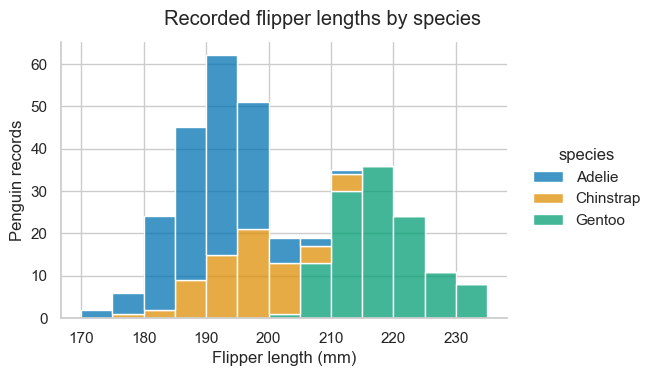

In [27]:
g = sns.displot(data=flipper_records, x="flipper_length_mm", hue="species",
                hue_order=species_order, bins=np.arange(170, 236, 5), multiple="stack",
                height=3.6, aspect=1.5)
g.set_axis_labels("Flipper length (mm)", "Penguin records")
g.figure.suptitle("Recorded flipper lengths by species", y=1.04)
plt.show()

# bivariate density and marginal plots

Density contours summarize a smoothed joint distribution; individual
observations are no longer visible. A joint plot combines a central
relationship plot with marginal distributions.

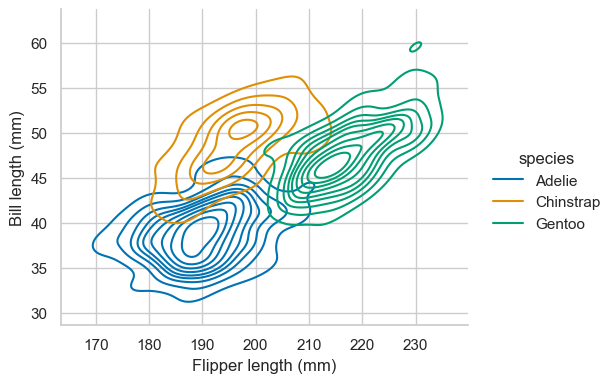

In [28]:
g = sns.displot(data=penguin_pairs, x="flipper_length_mm", y="bill_length_mm",
                hue="species", hue_order=species_order, kind="kde",
                height=4, aspect=1.25)
g.set_axis_labels("Flipper length (mm)", "Bill length (mm)")
plt.show()

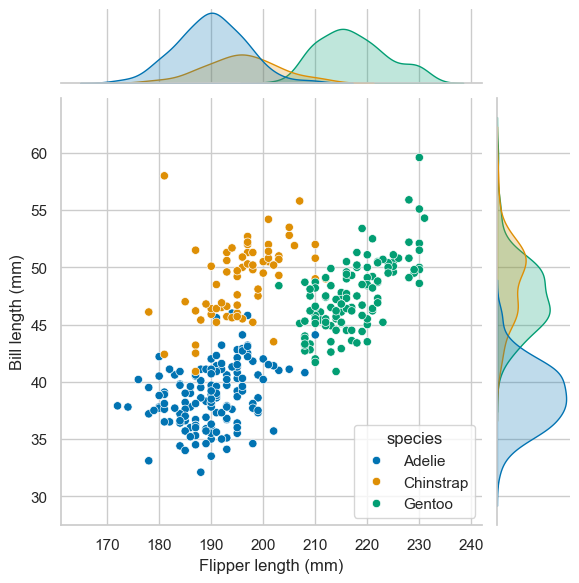

In [29]:
g = sns.jointplot(data=penguin_pairs, x="flipper_length_mm", y="bill_length_mm",
                  hue="species", hue_order=species_order, height=6)
g.set_axis_labels("Flipper length (mm)", "Bill length (mm)")
plt.show()

# pairwise comparisons in the iris example

`pairplot` makes many plots at once. Specify the measurement columns.
The four measurements in this local iris example are lengths in centimeters.

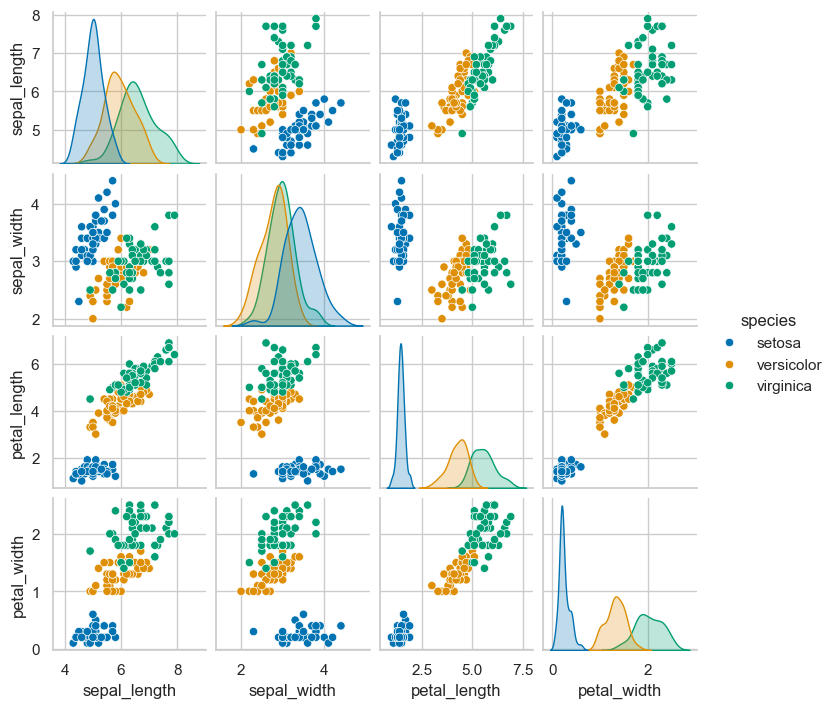

In [30]:
iris = pd.read_csv("../data/iris.csv")
iris_measurements = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
g = sns.pairplot(iris, vars=iris_measurements, hue="species", height=1.8)
plt.show()

# categorical plot variants with the tips data

In this dataset, one row is a recorded restaurant bill and tip.
`total_bill` and `tip` are monetary amounts; `size` records party size.
`day`, `time`, and the other recorded categories can define groups.

Set an explicit weekday order. A jittered strip plot moves points slightly
along the categorical axis to expose overlap. A swarm tries to avoid overlap by arranging the points.

In [31]:
tips = pd.read_csv("../data/tips.csv")
day_order = ["Thur", "Fri", "Sat", "Sun"]
time_order = ["Lunch", "Dinner"]
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


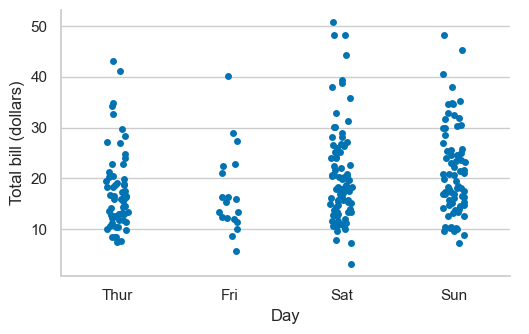

In [33]:
# Seaborn's jitter uses NumPy's global random state.
np.random.seed(21)
g = sns.catplot(data=tips, x="day", y="total_bill", order=day_order,
                kind="strip", jitter=True, height=3.5, aspect=1.5)
g.set_axis_labels("Day", "Total bill (dollars)")
plt.show()

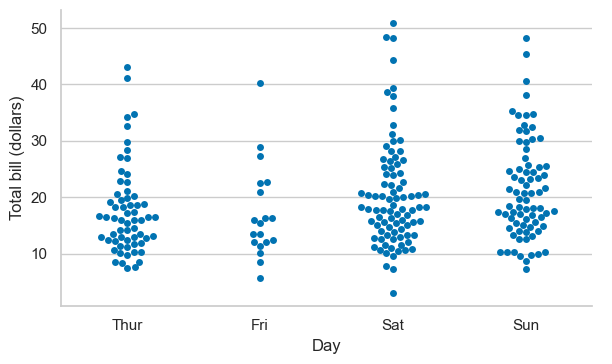

In [32]:
g = sns.catplot(data=tips, x="day", y="total_bill", order=day_order,
                kind="swarm", height=3.8, aspect=1.6)
g.set_axis_labels("Day", "Total bill (dollars)")
plt.show()

# boxes and violins plot

The boxplot and violin plot below use the same records. A violin adds a
smoothed density shape, so its appearance depends on smoothing and scaling.

`split=True` puts the two recorded-sex distributions on opposite sides.
Keep sample sizes available before interpreting small differences in shape.

In [34]:
tips.groupby(["day", "sex"], as_index=False).agg(n_bills=("total_bill", "count"))

,day,sex,n_bills
0,Fri,Female,9
1,Fri,Male,10
2,Sat,Female,28
3,Sat,Male,59
4,Sun,Female,18
5,Sun,Male,58
6,Thur,Female,32
7,Thur,Male,30


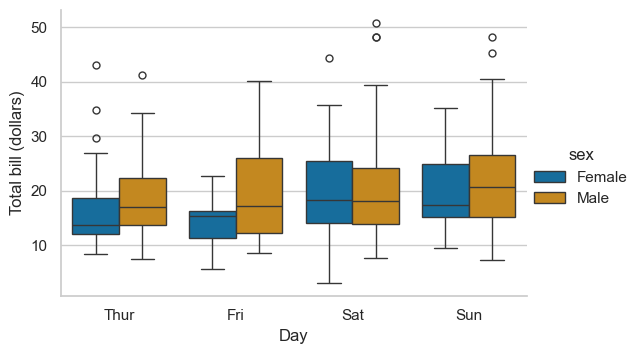

In [35]:
g = sns.catplot(data=tips, x="day", y="total_bill", hue="sex", order=day_order,
                kind="box", height=3.7, aspect=1.5)
g.set_axis_labels("Day", "Total bill (dollars)")
plt.show()

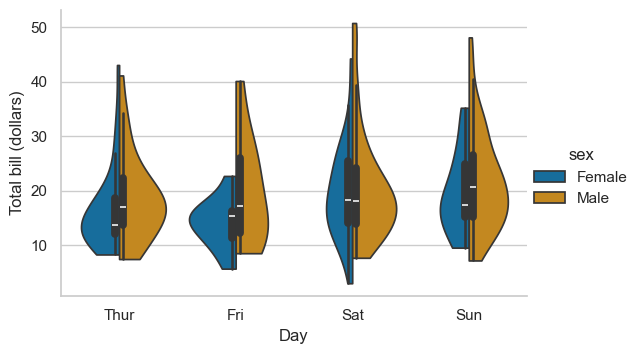

In [36]:
g = sns.catplot(data=tips, x="day", y="total_bill", hue="sex", order=day_order,
                kind="violin", split=True, cut=0, height=3.7, aspect=1.5)
g.set_axis_labels("Day", "Total bill (dollars)")
plt.show()

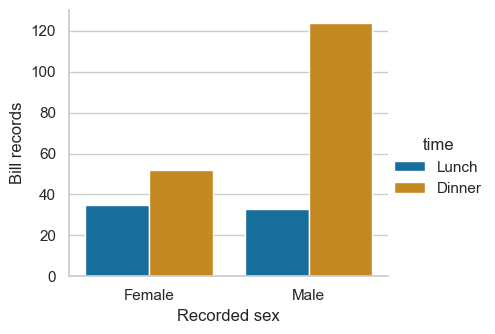

In [37]:
g = sns.catplot(data=tips, x="sex", hue="time", hue_order=time_order,
                kind="count", height=3.5, aspect=1.2)
g.set_axis_labels("Recorded sex", "Bill records")
plt.show()

# more faceting examples

Adding both `row` and `col` creates combinations of categories. Empty panels
or absent colors can reflect combinations with no usable records.

Records used for sex/island facets: 333


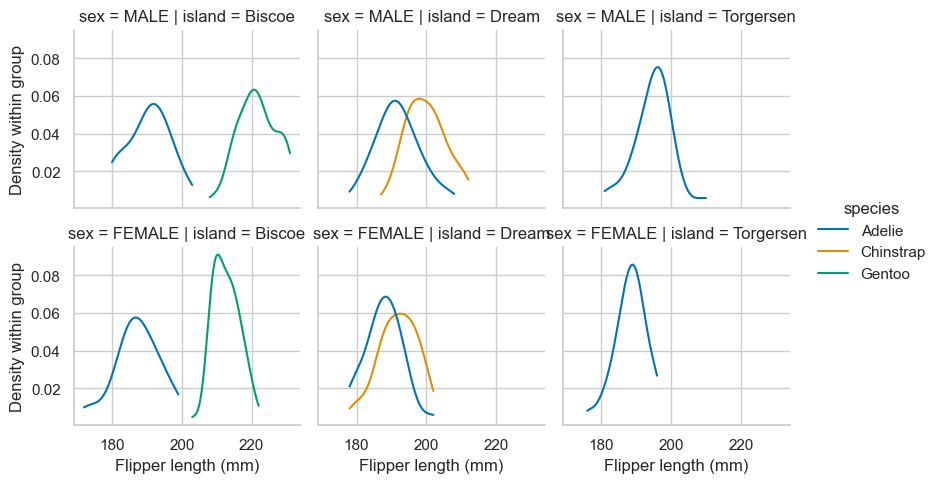

In [38]:
penguin_facets = penguins.dropna(subset=["flipper_length_mm", "species", "sex", "island"])
print("Records used for sex/island facets:", len(penguin_facets))
g = sns.displot(data=penguin_facets, x="flipper_length_mm", hue="species",
                hue_order=species_order, row="sex", col="island", col_order=island_order,
                kind="kde", common_norm=False, cut=0, height=2.5, aspect=1.1)
g.set_axis_labels("Flipper length (mm)", "Density within group")
plt.show()

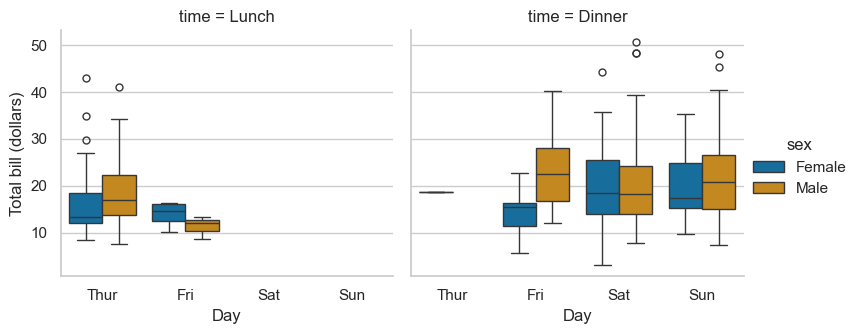

In [39]:
g = sns.catplot(data=tips, x="day", y="total_bill", hue="sex", col="time",
                order=day_order, col_order=time_order, kind="box", height=3.5, aspect=1.1)
g.set_axis_labels("Day", "Total bill (dollars)")
plt.show()

# map a Matplotlib function with FacetGrid

Figure-level functions usually handle faceting for us. A manual `FacetGrid`
is useful when we need to map another plotting function across the subsets.

Use the same bin edges across panels. With `density=True`, each panel's
histogram has area one; compare shapes while checking the panel sample sizes.

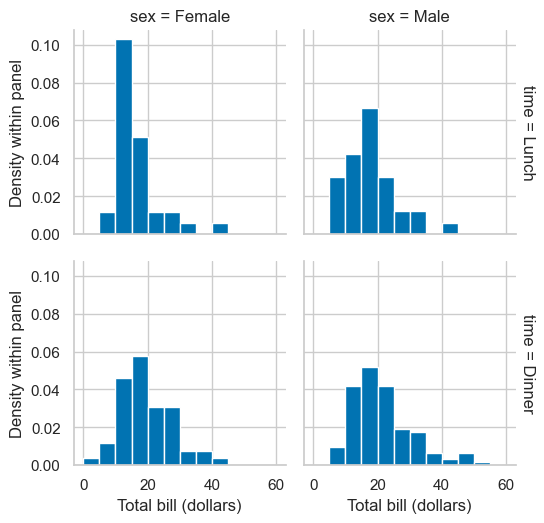

In [40]:
g = sns.FacetGrid(tips, row="time", col="sex", row_order=time_order,
                  margin_titles=True, height=2.7)
g.map(plt.hist, "total_bill", density=True, bins=np.arange(0, 61, 5), edgecolor="white")
g.set_axis_labels("Total bill (dollars)", "Density within panel")
plt.show()

# exploratory regression and residual plots

`lmplot` adds fitted linear relationships; `relplot` can show the same points
without a fitted model. A line summarizes an association under a model.

Here `ci=None` turns off regression intervals to focus on the fits.

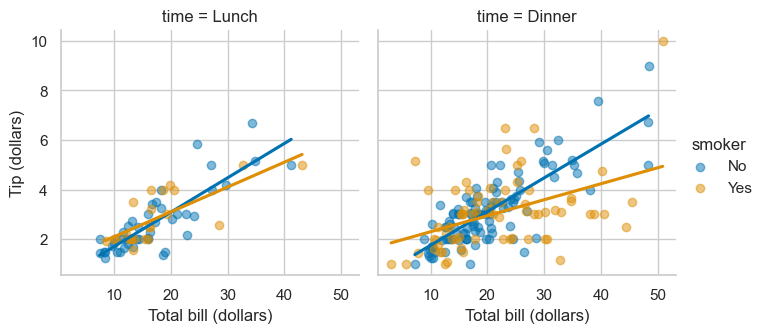

In [41]:
g = sns.lmplot(data=tips, x="total_bill", y="tip", hue="smoker", col="time",
               col_order=time_order, ci=None, scatter_kws={"alpha": 0.5}, height=3.5)
g.set_axis_labels("Total bill (dollars)", "Tip (dollars)")
plt.show()

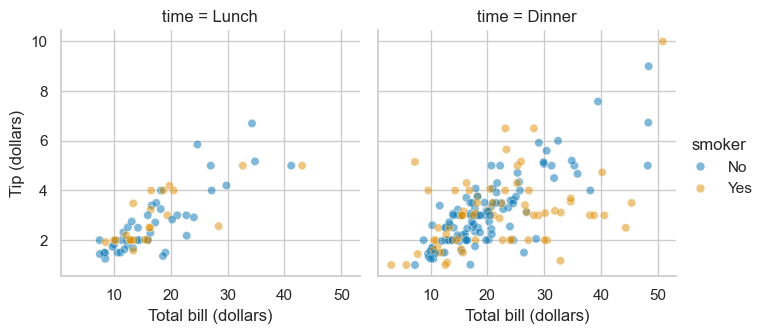

In [42]:
g = sns.relplot(data=tips, x="total_bill", y="tip", hue="smoker", col="time",
                col_order=time_order, alpha=0.5, height=3.5)
g.set_axis_labels("Total bill (dollars)", "Tip (dollars)")
plt.show()

A residual is an observed response minus its fitted value. The next plot
uses a single linear fit across all these bills, unlike the separate group
fits above. Look for structure left over after the fit, but do not treat the
absence of an obvious pattern as proof that every model assumption holds.

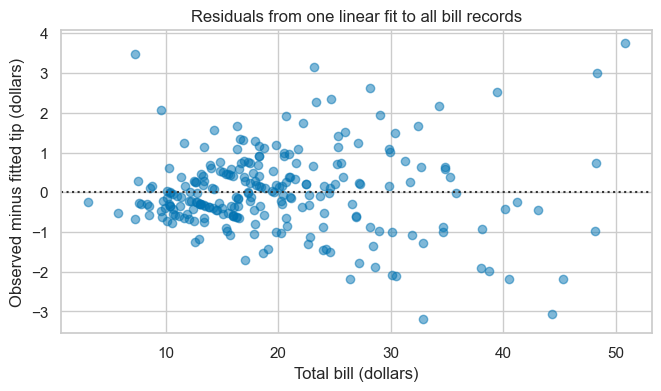

In [43]:
fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
sns.residplot(data=tips, x="total_bill", y="tip", scatter_kws={"alpha": 0.5}, ax=ax)
ax.set(title="Residuals from one linear fit to all bill records",
       xlabel="Total bill (dollars)", ylabel="Observed minus fitted tip (dollars)")
plt.show()

# References and example data

- [Seaborn function overview](https://seaborn.pydata.org/tutorial/function_overview.html)
- [Data structures](https://seaborn.pydata.org/tutorial/data_structure.html)
- [Distributions](https://seaborn.pydata.org/tutorial/distributions.html)
- [Statistical estimation and error bars](https://seaborn.pydata.org/tutorial/error_bars.html)
- [Alternate dataframe support](https://seaborn.pydata.org/whatsnew/v0.13.0.html#support-for-alternate-dataframe-libraries)
- [Seaborn example-data repository](https://github.com/mwaskom/seaborn-data)
- [Palmer Penguins data and provenance](https://allisonhorst.github.io/palmerpenguins/)
